In [1]:
"""
Hyperspectral Data Analysis for Enzyme Prediction using GA-PLS
================================================================
Complete pipeline for feature selection and modeling of maize enzyme concentrations
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy import signal
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ==============================================================================
# 1. DATA LOADING AND EXPLORATION
# ==============================================================================

def load_data(spectral_path, enzyme_path):
    """
    Load hyperspectral and enzyme concentration data
    
    Parameters:
    -----------
    spectral_path : str
        Path to CSV file with spectral data (samples x wavelengths)
    enzymes_path : str
        Path to CSV file with enzyme concentrations (samples x enzymes)
    """
    print("Loading data...")
    X = pd.read_csv(spectral_path)
    y = pd.read_csv(enzyme_path)
    # X = pd.read_csv('data/waves.csv')
    # y = pd.read_csv('data/enzymes.csv')
    
    print(f"Spectral data shape: {X.shape}")
    print(f"Enzyme data shape: {y.shape}")
    
    # Check for missing values
    print(f"\nMissing values in spectral data: {X.isnull().sum().sum()}")
    print(f"Missing values in enzyme data: {y.isnull().sum().sum()}")
    
    return X, y

def explore_data(X, y, wavelengths=None):
    """
    Visualize and explore the dataset
    """
    print("\n" + "="*70)
    print("DATA EXPLORATION")
    print("="*70)
    
    # Spectral data statistics
    print("\nSpectral Data Statistics:")
    print(f"Mean spectrum range: [{X.mean().min():.4f}, {X.mean().max():.4f}]")
    print(f"Std spectrum range: [{X.std().min():.4f}, {X.std().max():.4f}]")
    
    # Enzyme statistics
    print("\nEnzyme Concentration Statistics:")
    print(y.describe())
    
    # Plot mean spectrum with variability
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    
    mean_spectrum = X.mean(axis=0)
    std_spectrum = X.std(axis=0)
    x_axis = wavelengths
    
    axes[0].plot(x_axis, mean_spectrum, 'b-', linewidth=1.5, label='Mean')
    axes[0].fill_between(x_axis, mean_spectrum - std_spectrum, 
                          mean_spectrum + std_spectrum, alpha=0.3, label='±1 Std')
    axes[0].set_xlabel('Wavelength (nm)' if wavelengths is not None else 'Feature Index')
    axes[0].set_ylabel('Reflectance/Absorbance')
    axes[0].set_title('Mean Spectrum with Variability')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Plot enzyme distributions
    y.hist(bins=30, ax=axes[1], alpha=0.7, edgecolor='black')
    axes[1].set_title('Enzyme Concentration Distributions')
    axes[1].set_xlabel('Concentration')
    axes[1].set_ylabel('Frequency')
    
    plt.tight_layout()
    plt.show()
    plt.savefig('01_data_exploration.png', dpi=300, bbox_inches='tight')
    print("\nSaved: 01_data_exploration.png")
    plt.close()

In [3]:
# ==============================================================================
# 2. PREPROCESSING FUNCTIONS
# ==============================================================================

from sklearn.ensemble import IsolationForest

def remove_outliers(X, y):
    iso = IsolationForest(contamination=0.04, random_state=42)
    outliers = iso.fit_predict(X) == -1
    
    # Count and print the outliers
    num_outliers = outliers.sum()
    print(f"Number of outliers detected: {num_outliers}")

    if num_outliers > 0:
        print("Outlier values (X):")
        print(X[outliers])
        print("Corresponding target values (y):")
        print(y[outliers])
        
    X_clean, y_clean = X[~outliers], y[~outliers]
    
    return X_clean, y_clean, outliers


def snv(X):
    """
    Standard Normal Variate (SNV) transformation
    Removes multiplicative scatter effects
    """
    X_centered = X - X.mean(axis=1, keepdims=True)
    X_snv = X_centered / X.std(axis=1, keepdims=True)
    return X_snv

def msc(X):
    """
    Multiplicative Scatter Correction (MSC)
    """
    mean_spectrum = X.mean(axis=0)
    X_msc = np.zeros_like(X)
    
    for i in range(X.shape[0]):
        fit = np.polyfit(mean_spectrum, X[i, :], 1)
        X_msc[i, :] = (X[i, :] - fit[1]) / fit[0]
    
    return X_msc

def savitzky_golay_smooth(X, window_length=11, polyorder=2):
    """
    Savitzky-Golay smoothing filter
    """
    X_smooth = np.zeros_like(X)
    for i in range(X.shape[0]):
        X_smooth[i, :] = savgol_filter(X[i, :], window_length, polyorder)
    return X_smooth

# def savitzky_golay_derivative(X, deriv=1, window_length=11, polyorder=2):
#     """
#     Savitzky-Golay derivative (1st or 2nd order)
#     """
#     X_deriv = np.zeros_like(X)
#     for i in range(X.shape[0]):
#         X_deriv[i, :] = savgol_filter(X[i, :], window_length, polyorder, deriv=deriv)
#     return X_deriv

def preprocess_pipeline(X, baseline='msc', smooth=True, derivative=None, 
                        window_length=11, polyorder=2):
    """
    Complete preprocessing pipeline
    
    Parameters:
    -----------
    X : array-like
        Spectral data
    baseline : str
        'snv', 'msc', or None
    smooth : bool
        Apply Savitzky-Golay smoothing
    derivative : int or None
        Apply 1st or 2nd derivative, or None
    window_length : int
        Window for Savitzky-Golay filter (must be odd)
    polyorder : int
        Polynomial order for Savitzky-Golay filter
    """
    print("\n" + "="*70)
    print("PREPROCESSING")
    print("="*70)
    
    X_processed = X.copy()
    
    # Smoothing
    if smooth:
        print(f"Applying Savitzky-Golay smoothing (window={window_length}, poly={polyorder})...")
        X_processed = savitzky_golay_smooth(X_processed, window_length, polyorder)

    # Baseline correction
    if baseline == 'snv':
        print("Applying SNV (Standard Normal Variate)...")
        X_processed = snv(X_processed)
    elif baseline == 'msc':
        print("Applying MSC (Multiplicative Scatter Correction)...")
        X_processed = msc(X_processed)
    
    
    # Derivative
    # if derivative in [1, 2]:
    #     print(f"Applying {derivative}{'st' if derivative==1 else 'nd'} derivative transformation...")
    #     # X_processed = savitzky_golay_derivative(X_processed, derivative, window_length, polyorder)
    
    print("Preprocessing complete!")
    return X_processed

def visualize_preprocessing(X_raw, X_processed, sample_idx=1, wavelengths=None):
    """
    Visualize preprocessing effects
    """
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    
    x_axis = wavelengths if wavelengths is not None else np.arange(X_raw.shape[1])
    
    axes[0].plot(x_axis, X_raw[sample_idx], 'b-', linewidth=1.5, label='Raw')
    axes[0].set_xlabel('Wavelength (nm)' if wavelengths is not None else 'Feature Index')
    axes[0].set_ylabel('Intensity')
    axes[0].set_title('Raw Spectrum (Sample 1)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(x_axis, X_processed[sample_idx], 'r-', linewidth=1.5, label='Preprocessed')
    axes[1].set_xlabel('Wavelength (nm)' if wavelengths is not None else 'Feature Index')
    axes[1].set_ylabel('Intensity')
    axes[1].set_title('Preprocessed Spectrum (Sample 1)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    plt.savefig('02_preprocessing_comparison.png', dpi=300, bbox_inches='tight')
    print("\nSaved: 02_preprocessing_comparison.png")
    plt.close()



HYPERSPECTRAL GA-PLS PIPELINE
Loading data...
Spectral data shape: (262, 1867)
Enzyme data shape: (262, 5)

Missing values in spectral data: 0
Missing values in enzyme data: 0

DATA EXPLORATION

Spectral Data Statistics:
Mean spectrum range: [0.1358, 1.4416]
Std spectrum range: [0.0608, 0.1891]

Enzyme Concentration Statistics:
                  0             1            2             3           4
count    262.000000    262.000000   262.000000    262.000000  262.000000
mean    2262.995210   2187.796978   632.750286   1992.357929    0.689928
std     1878.432128   2983.730816  1329.626812   2513.595281    1.797702
min       60.457715      0.000000     0.000000      0.000000    0.000000
25%     1001.897558    565.672935    25.039861      3.438299    0.000000
50%     1854.196934   1012.698828    80.457697   1315.529036    0.000000
75%     3025.382083   2379.473821   551.548826   2795.063640    0.378290
max    14928.435290  19932.201530  6367.691872  16345.518440   17.689908


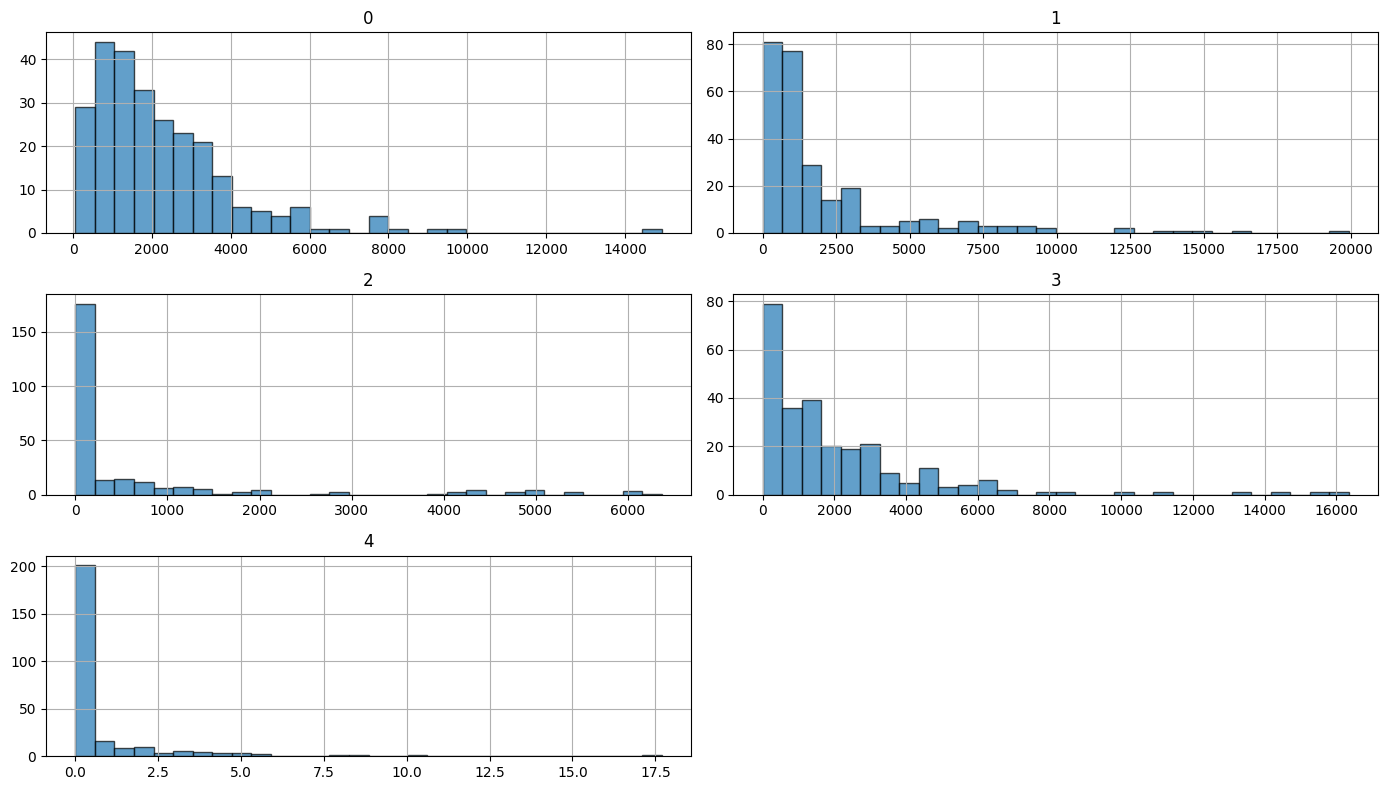


Saved: 01_data_exploration.png
Number of outliers detected: 11
Outlier values (X):
[[ 0.9141037   1.008995    1.029056   ... -0.06502139 -0.06477568
  -0.06468958]
 [ 1.299842    1.283169    1.386707   ...  0.3203063   0.3202472
   0.320182  ]
 [ 1.414659    1.326538    1.345896   ...  0.3547938   0.3537387
   0.3531892 ]
 ...
 [ 0.8891448   1.05208     1.190228   ...  0.2203151   0.2201398
   0.2205692 ]
 [ 1.271182    1.502196    1.596985   ...  0.2446101   0.2435008
   0.2437963 ]
 [ 0.          1.690472    1.433416   ...  0.05931595  0.05883365
   0.05852154]]
Corresponding target values (y):
[[5.56090537e+02 1.20139145e+03 5.40883589e+03 0.00000000e+00
  0.00000000e+00]
 [3.52504096e+03 8.88801402e+02 7.27559809e+01 2.06642189e+03
  1.15804994e+00]
 [1.25034928e+03 1.82016171e+03 1.18412982e+01 1.53441802e+03
  0.00000000e+00]
 [1.95782045e+03 2.21188023e+03 3.63600828e+01 2.12730281e+03
  0.00000000e+00]
 [3.49745464e+03 3.00177096e+03 6.41256041e+01 3.07854219e+03
  0.00000000e

In [4]:
# ==============================================================================
# USAGE EXAMPLE
# ==============================================================================

# Define file paths
spectral_path = 'data/waves.csv'
enzyme_path = 'data/enzymes.csv'

# Optional: Define wavelengths and enzyme names
wavelengths = np.arange(1, 1868, 1)  # Use feature indices if wavelengths unknown

enzyme_names = ['Enzyme_1', 'Enzyme_2', 'Enzyme_3', 'Enzyme_4', 'Enzyme_5']

print("\n" + "="*70)
print("HYPERSPECTRAL GA-PLS PIPELINE")
print("="*70)

# 1. Load data
X, y = load_data(spectral_path, enzyme_path)

# 2. Data exploration
explore_data(X, y, wavelengths)

X = X.values if isinstance(X, pd.DataFrame) else X
y = y.values if isinstance(y, pd.DataFrame) else y

# 3. Remove outliers
X, y, outliers = remove_outliers(X, y)

In [5]:
print(X.shape, y.shape)

(251, 1867) (251, 5)



PREPROCESSING
Applying Savitzky-Golay smoothing (window=11, poly=2)...
Applying SNV (Standard Normal Variate)...
Preprocessing complete!


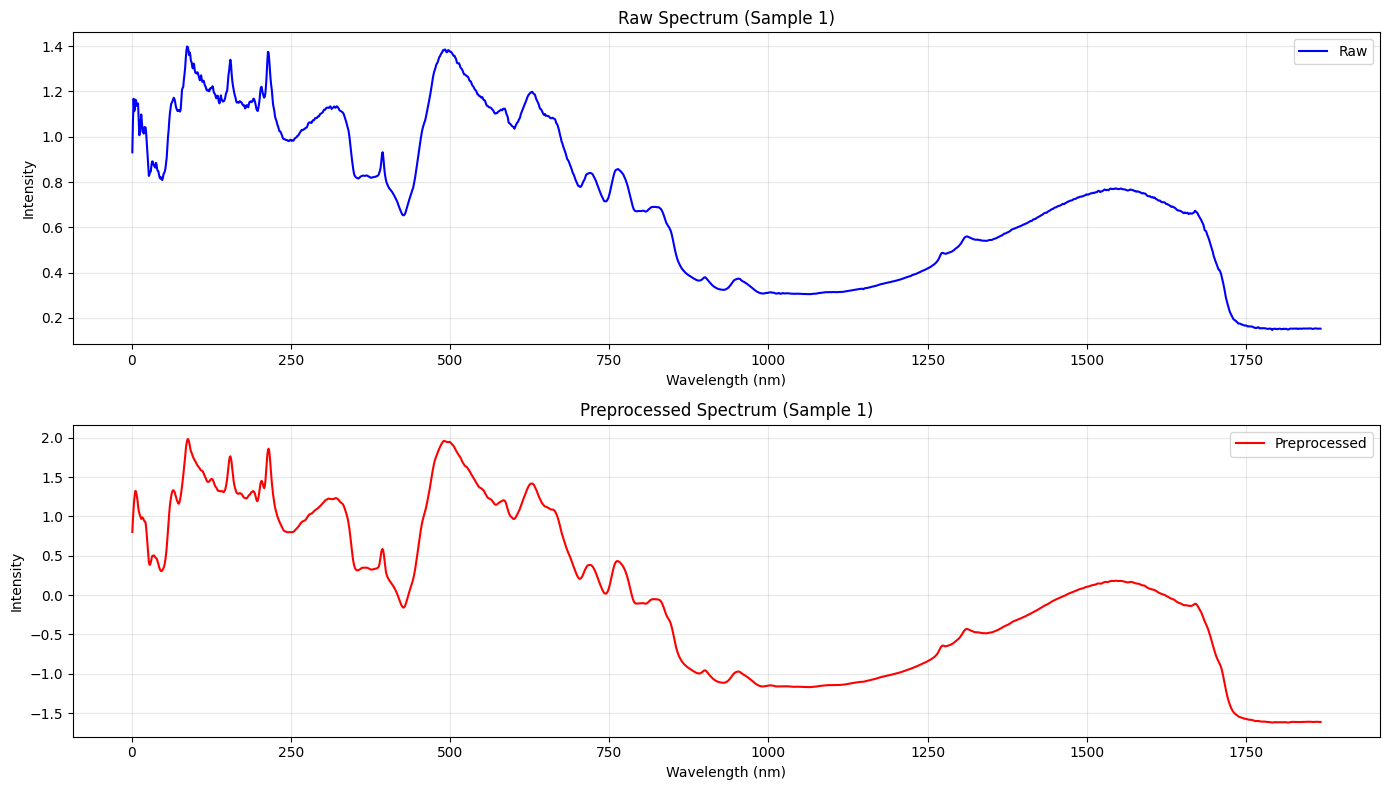


Saved: 02_preprocessing_comparison.png

Analysis complete! Check the generated files:
- 02_preprocessing_comparison.png


In [6]:
# 4. Preprocessing
X_raw = X.copy()
X_processed = preprocess_pipeline(X, baseline='snv', smooth=True, 
                                    derivative=1, window_length=11,
                                    polyorder=2)
visualize_preprocessing(X_raw, X_processed, sample_idx=0, wavelengths=wavelengths)

print("\nAnalysis complete! Check the generated files:")
print("- 02_preprocessing_comparison.png")


PREPROCESSING
Applying Savitzky-Golay smoothing (window=11, poly=2)...
Applying MSC (Multiplicative Scatter Correction)...
Preprocessing complete!


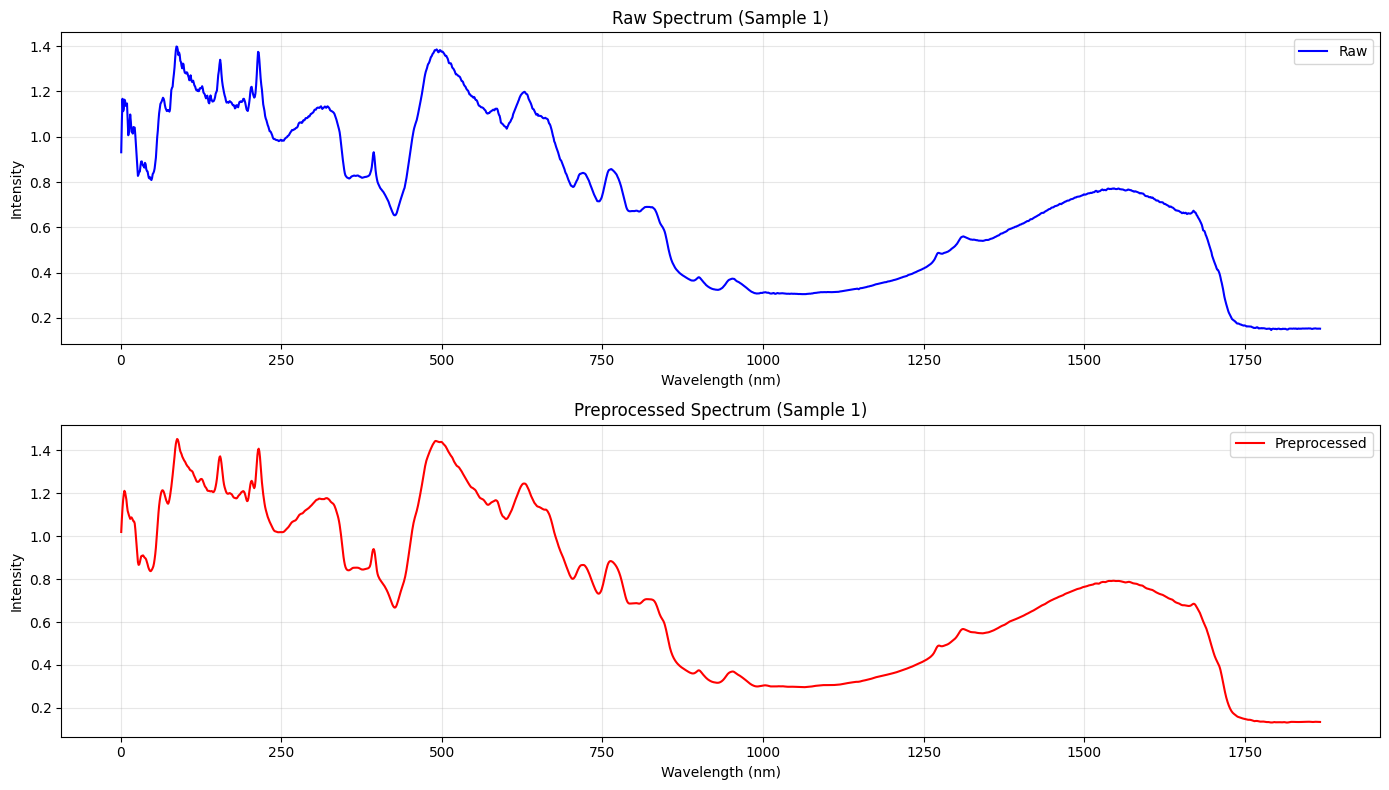


Saved: 02_preprocessing_comparison.png

Analysis complete! Check the generated files:
- 02_preprocessing_comparison.png


In [7]:
# 4. Preprocessing
X_raw = X.copy()
X_processed2 = preprocess_pipeline(X, baseline='msc', smooth=True, 
                                    derivative=1, window_length=11,
                                    polyorder=2)
visualize_preprocessing(X_raw, X_processed2, sample_idx=0, wavelengths=wavelengths)

print("\nAnalysis complete! Check the generated files:")
print("- 02_preprocessing_comparison.png")

In [8]:
# 5. Train-test split (BEFORE feature selection!)
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.2, random_state=42
)
print(f"\nTrain set: {X_train.shape[0]} samples and {X_train.shape[1]} features")
print(f"Test set: {X_test.shape[0]} samples and {X_test.shape[1]} features")
print(f"\nTrain set: {y_train.shape[0]} samples and {y_train.shape[1]} labels")
print(f"Test set: {y_test.shape[0]} samples and {y_test.shape[1]} labels")


Train set: 200 samples and 1867 features
Test set: 51 samples and 1867 features

Train set: 200 samples and 5 labels
Test set: 51 samples and 5 labels


In [9]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import VarianceThreshold
from sklearn.cross_decomposition import PLSRegression

# === 1️⃣ VARIANCE FILTER ===
# Remove wavelengths with very low variance across samples
var_thresh = 1e-5
var_selector = VarianceThreshold(threshold=var_thresh)
X_train_var = var_selector.fit_transform(X_train)
X_test_var = var_selector.transform(X_test)
mask_var = var_selector.get_support()
print(f"Variance filter → kept {X_train_var.shape[1]} features (removed {np.sum(~mask_var)})")

Variance filter → kept 1867 features (removed 0)


In [10]:
# === 2️⃣ CORRELATION FILTER ===
# Compute correlation of each wavelength with any enzyme
corr_threshold = 0.01
corrs = np.corrcoef(X_train[:, mask_var], y_train, rowvar=False)
corrs_xy = corrs[:X_train_var.shape[1], X_train_var.shape[1]:]  # X vs Y block
max_corr = np.nanmax(np.abs(corrs_xy), axis=1)       # strongest correlation per wavelength
mask_corr = max_corr > corr_threshold

X_train_corr = X_train_var[:, mask_corr]
X_test_corr = X_test_var[:, mask_corr]
print(f"Correlation filter → kept {X_train_corr.shape[1]} features (removed {np.sum(~mask_corr)})")

Correlation filter → kept 1867 features (removed 0)


In [11]:
print(X_train_corr.shape[0])
print(y_train.shape[0])


200
200


In [12]:
# PSO + PLS feature selection (with hard top-K constraint)
# Requirements: numpy, pandas, sklearn
import numpy as np
import pandas as pd
import time
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")
np.random.seed(42)

# ---------- metrics ----------
def rmse(y_true, y_pred): return np.sqrt(mean_squared_error(y_true, y_pred))
def rpd(y_ref, y_pred):
    sd = np.std(y_ref, ddof=1)
    denom = rmse(y_ref, y_pred)
    return sd/denom if denom != 0 else np.inf

# ---------- helper ----------
def choose_n_components(X, y, max_components=15):
    return min(max_components, X.shape[0]-1, X.shape[1])

def quantile_strat_split_single_y(X, y, test_size=0.2, q=10, random_state=0):
    # bin into quantiles to keep distribution similar
    bins = np.unique(np.nanpercentile(y, np.linspace(0,100,q+1)))
    digitized = np.digitize(y, bins[1:-1], right=True)
    return train_test_split(X, y, test_size=test_size, stratify=digitized, random_state=random_state)

# ---------- CV fitness (returns RMSECV, can include penalty) ----------
def fitness_mask_cv(mask_indices, X, y, n_splits=5, random_state=0, multiplicative_penalty_lambda=0.0):
    if len(mask_indices) == 0:
        return 1e6
    Xsel = X[:, mask_indices]
    n_comp = max(1, choose_n_components(Xsel, y, max_components=10))
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    preds = np.zeros_like(y, dtype=float)
    for train_idx, val_idx in kf.split(Xsel):
        pls = PLSRegression(n_components=n_comp)
        pls.fit(Xsel[train_idx], y[train_idx])
        preds[val_idx] = pls.predict(Xsel[val_idx]).ravel()
    cv_rmse = rmse(y, preds)
    if multiplicative_penalty_lambda and X.shape[1] > 0:
        frac = len(mask_indices) / X.shape[1]
        cv_rmse = cv_rmse * (1.0 + multiplicative_penalty_lambda * frac)
    return cv_rmse

# ---------- Binary PSO core with top-K enforcement ----------
class TopKBinaryPSO:
    def __init__(self, dim, swarm_size=40, w=0.7, c1=1.5, c2=1.5, vmax=4.0, seed=0,
                 min_features=5, max_features=120, keep_topk=True):
        self.dim = dim
        self.swarm_size = swarm_size
        rng = np.random.RandomState(seed)
        self.pos = rng.randn(swarm_size, dim) * 0.01  # real-coded "scores" (logits)
        self.vel = rng.randn(swarm_size, dim) * 0.01
        self.pbest_pos = self.pos.copy()
        self.pbest_val = np.full(swarm_size, np.inf)
        self.gbest_pos = None
        self.gbest_val = np.inf
        self.w, self.c1, self.c2, self.vmax = w, c1, c2, vmax
        self.rng = rng
        self.min_features = min_features
        self.max_features = max_features
        self.keep_topk = keep_topk

    def _sigmoid(self, x):
        return 1.0 / (1.0 + np.exp(-x))

    def _pos_to_mask_topk(self, pos_logits):
        probs = self._sigmoid(pos_logits)

        # 1) base mask using probability threshold
        mask = (probs > 0.5).astype(int)
        n = mask.sum()

        # 2) if too many → keep the best ones by prob
        if n > self.max_features:
            keep = np.argsort(-probs)[:self.max_features]
            new_mask = np.zeros_like(mask)
            new_mask[keep] = 1
            mask = new_mask
            n = mask.sum()

        # 3) if too few → add random high-prob ones
        if n < self.min_features:
            deficit = self.min_features - n
            candidates = np.argsort(-probs)  # sorted by probability
            add = []
            for c in candidates:
                if mask[c] == 0:
                    add.append(c)
                if len(add) == deficit:
                    break
            mask[add] = 1

        return mask, probs


    def step(self, fitness_function):
        # evaluate current swarm
        for i in range(self.swarm_size):
            mask, probs = self._pos_to_mask_topk(self.pos[i])
            indices = np.where(mask==1)[0]
            val = fitness_function(indices)
            if val < self.pbest_val[i]:
                self.pbest_val[i] = val
                self.pbest_pos[i] = self.pos[i].copy()
            if val < self.gbest_val:
                self.gbest_val = val
                self.gbest_pos = self.pos[i].copy()
        # update velocities and positions
        for i in range(self.swarm_size):
            r1 = self.rng.rand(self.dim)
            r2 = self.rng.rand(self.dim)
            cognitive = self.c1 * r1 * (self.pbest_pos[i] - self.pos[i])
            social = self.c2 * r2 * (self.gbest_pos - self.pos[i])
            self.vel[i] = self.w * self.vel[i] + cognitive + social
            # clamp velocity
            self.vel[i] = np.clip(self.vel[i], -self.vmax, self.vmax)
            self.pos[i] += self.vel[i]
            # numerically stable bounds
            self.pos[i] = np.clip(self.pos[i], -20, 20)

    def get_best_mask_and_probs(self):
        mask, probs = self._pos_to_mask_topk(self.gbest_pos)
        return mask, probs

# ---------- function to run PSO for one enzyme ----------
def run_pso_select(X_train, y_train, X_test, y_test, enzyme_name="E", *,
                   swarm_size=60, generations=80, min_features=5, max_features=120,
                   multiplicative_penalty_lambda=0.0, random_state=0, verbose=True):
    dim = X_train.shape[1]
    pso = TopKBinaryPSO(dim, swarm_size=swarm_size, seed=random_state,
                        min_features=min_features, max_features=max_features)
    # fitness wrapper uses CV on training set
    def fit_wrapper(selected_idx):
        return fitness_mask_cv(selected_idx, X_train, y_train, n_splits=5, random_state=random_state,
                               multiplicative_penalty_lambda=multiplicative_penalty_lambda)

    history = []
    t0 = time.time()
    for gen in range(1, generations+1):
        pso.step(fit_wrapper)
        best_mask, best_probs = pso.get_best_mask_and_probs()
        sel_idx = np.where(best_mask==1)[0]
        n_sel = sel_idx.size
        # compute CV RMSE without penalty for reporting
        cv_rmse = fitness_mask_cv(sel_idx, X_train, y_train, n_splits=5, random_state=random_state,
                                  multiplicative_penalty_lambda=0.0)
        elapsed = time.time() - t0
        history.append((gen, cv_rmse, n_sel))
        if verbose and (gen % max(1, generations//20) == 0 or gen <= 5):
            print(f"[{enzyme_name}] Gen {gen:03d}/{generations} | CV_RMSE: {cv_rmse:.4f} | n_features: {n_sel} | elapsed: {elapsed:.1f}s")
    # final selection and final PLS fit
    best_mask, best_probs = pso.get_best_mask_and_probs()
    sel_idx = np.where(best_mask==1)[0]
    n_comp = max(1, choose_n_components(X_train[:, sel_idx], y_train, max_components=10))
    pls = PLSRegression(n_components=n_comp)
    pls.fit(X_train[:, sel_idx], y_train)
    y_pred_test = pls.predict(X_test[:, sel_idx]).ravel()
    test_rmse = rmse(y_test, y_pred_test)
    test_r2 = r2_score(y_test, y_pred_test)
    test_rpd = rpd(y_test, y_pred_test)
    result = {
        "selected_idx": sel_idx,
        "n_selected": int(sel_idx.size),
        "pls_model": pls,
        "y_pred_test": y_pred_test,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "test_rpd": test_rpd,
        "history": history,
        "best_probs": best_probs
    }
    if verbose:
        print(f"[{enzyme_name}] DONE | Test RMSE: {test_rmse:.4f} | R2: {test_r2:.4f} | RPD: {test_rpd:.3f} | n_features: {sel_idx.size}")
    return result

# ---------- wrapper to run across all enzymes ----------
def run_feature_selection_all_enzymes(X, Y, enzyme_names=None, *,
                                      swarm_size=60, generations=80,
                                      min_features=5, max_features=120,
                                      multiplicative_penalty_lambda=0.25,
                                      random_state=0):
    n_enz = Y.shape[1]
    if enzyme_names is None:
        enzyme_names = [f"E{i+1}" for i in range(n_enz)]
    results = {}
    for i in range(n_enz):
        print("\n" + "="*60)
        name = enzyme_names[i]
        y = Y[:, i].ravel()
        # decide transform
        skew = pd.Series(y).skew()
        transform = None
        if skew > 2 or (np.max(y) / (np.median(y)+1e-9) > 50):
            transform = "log1p"
            y_proc = np.log1p(y)
            print(f"[{name}] Applied log1p transform (skew {skew:.2f})")
        else:
            y_proc = y.copy()
        # stratified split
        Xtr, Xte, ytr, yte = quantile_strat_split_single_y(X, y_proc, test_size=0.2, q=10, random_state=random_state)
        # standardize X
        scaler = StandardScaler()
        Xtr_s = scaler.fit_transform(Xtr)
        Xte_s = scaler.transform(Xte)
        print(f"[{name}] Training samples: {Xtr_s.shape[0]} | Features: {Xtr_s.shape[1]}")
        # run PSO selection
        res = run_pso_select(Xtr_s, ytr, Xte_s, yte, enzyme_name=name,
                             swarm_size=swarm_size, generations=generations,
                             min_features=min_features, max_features=max_features,
                             multiplicative_penalty_lambda=multiplicative_penalty_lambda,
                             random_state=random_state, verbose=True)
        # inverse transform for reporting
        if transform == "log1p":
            yte_orig = np.expm1(yte)
            ypred_orig = np.expm1(res["y_pred_test"])
            rmse_test = rmse(yte_orig, ypred_orig)
            r2_test = r2_score(yte_orig, ypred_orig)
            rpd_test = rpd(yte_orig, ypred_orig)
        else:
            rmse_test = res["test_rmse"]
            r2_test = res["test_r2"]
            rpd_test = res["test_rpd"]
        results[name] = {
            "n_selected": res["n_selected"],
            "selected_idx": res["selected_idx"],
            "rmse_test": float(rmse_test),
            "r2_test": float(r2_test),
            "rpd_test": float(rpd_test),
            "transform": transform,
            "history": res["history"]
        }
        print(f"[{name}] Final (orig scale) RMSE: {rmse_test:.4f} | R2: {r2_test:.4f} | RPD: {rpd_test:.3f} | n_features: {res['n_selected']}")
    # summary df
    print("\n" + "="*60)
    df = pd.DataFrame.from_dict({k:{'n_selected':v['n_selected'],
                                    'rmse_test':v['rmse_test'],
                                    'r2_test':v['r2_test'],
                                    'rpd_test':v['rpd_test'],
                                    'transform':v['transform']} for k,v in results.items()}, orient='index')
    print("SUMMARY:")
    print(df)
    return results




In [13]:
# ---------------------------
# USAGE:

enzyme_names = ["E1","E2","E3","E4","E5"]

results = run_feature_selection_all_enzymes(X_processed, y, enzyme_names=enzyme_names,
                                           swarm_size=60, generations=200,
                                           min_features=30, max_features=100,
                                           multiplicative_penalty_lambda=0.25,
                                           random_state=42)


[E1] Applied log1p transform (skew 2.29)
[E1] Training samples: 200 | Features: 1867
[E1] Gen 001/200 | CV_RMSE: 0.7599 | n_features: 100 | elapsed: 0.5s
[E1] Gen 002/200 | CV_RMSE: 0.7575 | n_features: 100 | elapsed: 1.0s
[E1] Gen 003/200 | CV_RMSE: 0.7458 | n_features: 100 | elapsed: 1.4s
[E1] Gen 004/200 | CV_RMSE: 0.7312 | n_features: 100 | elapsed: 1.9s
[E1] Gen 005/200 | CV_RMSE: 0.7154 | n_features: 100 | elapsed: 2.4s
[E1] Gen 010/200 | CV_RMSE: 0.7029 | n_features: 100 | elapsed: 4.6s
[E1] Gen 020/200 | CV_RMSE: 0.6871 | n_features: 100 | elapsed: 9.0s
[E1] Gen 030/200 | CV_RMSE: 0.6819 | n_features: 100 | elapsed: 14.1s
[E1] Gen 040/200 | CV_RMSE: 0.6755 | n_features: 100 | elapsed: 20.6s
[E1] Gen 050/200 | CV_RMSE: 0.6719 | n_features: 100 | elapsed: 28.7s
[E1] Gen 060/200 | CV_RMSE: 0.6652 | n_features: 100 | elapsed: 37.2s
[E1] Gen 070/200 | CV_RMSE: 0.6622 | n_features: 100 | elapsed: 46.3s
[E1] Gen 080/200 | CV_RMSE: 0.6608 | n_features: 100 | elapsed: 53.3s
[E1] Gen 09

In [14]:
# ---------------------------
# USAGE:

enzyme_names = ["E1","E2","E3","E4","E5"]

results = run_feature_selection_all_enzymes(X_processed, y, enzyme_names=enzyme_names,
                                           swarm_size=60, generations=200,
                                           min_features=30, max_features=50,
                                           multiplicative_penalty_lambda=0.25,
                                           random_state=42)


[E1] Applied log1p transform (skew 2.29)
[E1] Training samples: 200 | Features: 1867
[E1] Gen 001/200 | CV_RMSE: 0.7302 | n_features: 50 | elapsed: 0.4s
[E1] Gen 002/200 | CV_RMSE: 0.7302 | n_features: 50 | elapsed: 0.8s
[E1] Gen 003/200 | CV_RMSE: 0.7271 | n_features: 50 | elapsed: 1.3s
[E1] Gen 004/200 | CV_RMSE: 0.7211 | n_features: 50 | elapsed: 1.7s
[E1] Gen 005/200 | CV_RMSE: 0.7154 | n_features: 50 | elapsed: 2.2s
[E1] Gen 010/200 | CV_RMSE: 0.7038 | n_features: 50 | elapsed: 4.3s
[E1] Gen 020/200 | CV_RMSE: 0.6888 | n_features: 50 | elapsed: 8.7s
[E1] Gen 030/200 | CV_RMSE: 0.6788 | n_features: 50 | elapsed: 13.8s
[E1] Gen 040/200 | CV_RMSE: 0.6721 | n_features: 50 | elapsed: 18.6s
[E1] Gen 050/200 | CV_RMSE: 0.6695 | n_features: 50 | elapsed: 23.6s
[E1] Gen 060/200 | CV_RMSE: 0.6667 | n_features: 50 | elapsed: 29.1s
[E1] Gen 070/200 | CV_RMSE: 0.6594 | n_features: 50 | elapsed: 34.0s
[E1] Gen 080/200 | CV_RMSE: 0.6579 | n_features: 50 | elapsed: 38.6s
[E1] Gen 090/200 | CV_RM